# Melanoma & Nevus Dermoscopy Dataset - EDA

##### 1. Load dữ liệu train/val/test

In [2]:
import pandas as pd

df_train = pd.read_csv("data/splitted/train.csv")
df_val = pd.read_csv("data/splitted/val.csv")
df_test = pd.read_csv("data/splitted/test.csv")

print("Train:", df_train.shape)
print("Val  :", df_val.shape)
print("Test :", df_test.shape)

Train: (12696, 10)
Val  : (2752, 10)
Test : (2685, 10)


In [3]:
df_train

,isic_id,attribution,age_approx,anatom_site_general,concomitant_biopsy,diagnosis,lesion_id,melanocytic,patient_id,sex
0,ISIC_0000002,Anonymous,60.0,upper extremity,True,melanoma,NaN,True,NaN,female
1,ISIC_0000004,Anonymous,80.0,posterior torso,True,melanoma,NaN,True,NaN,male
2,ISIC_0000013,Anonymous,30.0,posterior torso,True,melanoma,NaN,True,NaN,female
3,ISIC_0000026,Anonymous,30.0,lower extremity,True,melanoma,NaN,True,NaN,female
4,ISIC_0000030,Anonymous,55.0,lower extremity,True,melanoma,NaN,True,NaN,female
...,...,...,...,...,...,...,...,...,...,...
12691,ISIC_9967383,The University of Queensland Diamantina Instit...,55.0,NaN,False,melanoma,IL_2267077,NaN,IP_7887363,male
12692,ISIC_9975949,Memorial Sloan Kettering Cancer Center,40.0,NaN,True,nevus,IL_1216689,True,IP_9245079,male
12693,ISIC_9977219,"ViDIR Group, Department of Dermatology, Medica...",60.0,NaN,True,nevus,IL_4637503,True,IP_2673125,male
12694,ISIC_9997614,Memorial Sloan Kettering Cancer Center,50.0,upper extremity,True,nevus,IL_5910182,True,IP_1705144,female


In [4]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12696 entries, 0 to 12695
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   isic_id              12696 non-null  object 
 1   attribution          12696 non-null  object 
 2   age_approx           12372 non-null  float64
 3   anatom_site_general  11911 non-null  object 
 4   concomitant_biopsy   12696 non-null  bool   
 5   diagnosis            12696 non-null  object 
 6   lesion_id            9831 non-null   object 
 7   melanocytic          12386 non-null  object 
 8   patient_id           3499 non-null   object 
 9   sex                  12422 non-null  object 
dtypes: bool(1), float64(1), object(8)
memory usage: 905.2+ KB


##### 2. Phân phối age_approx

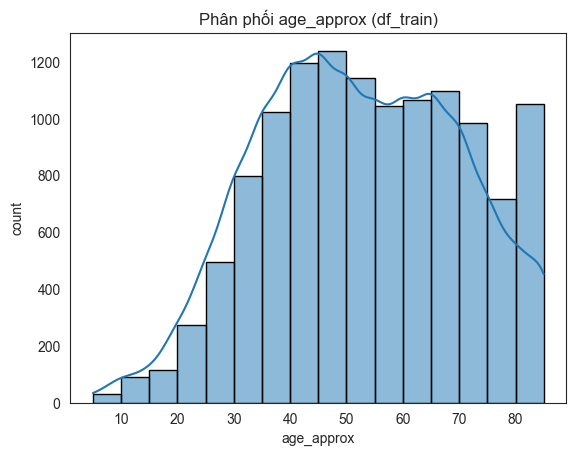

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

sns.set_style('white')

bin_width = 5
age = df_train['age_approx'].dropna()
age_min = age.min()
age_max = age.max()
bins = np.arange(age_min, age_max + bin_width, bin_width)

fig, ax = plt.subplots()
sns.histplot(age, bins=bins, kde=True, edgecolor='black', ax=ax)

ax.set_xlabel('age_approx')
ax.set_ylabel('count')
ax.set_title('Phân phối age_approx (df_train)')
plt.show()

##### 3. Phân phối các biến category có missing

C:\Users\l20f9\AppData\Local\Temp\ipykernel_3892\1541554831.py:15: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data = df_train[c].astype('object').fillna('NaN')


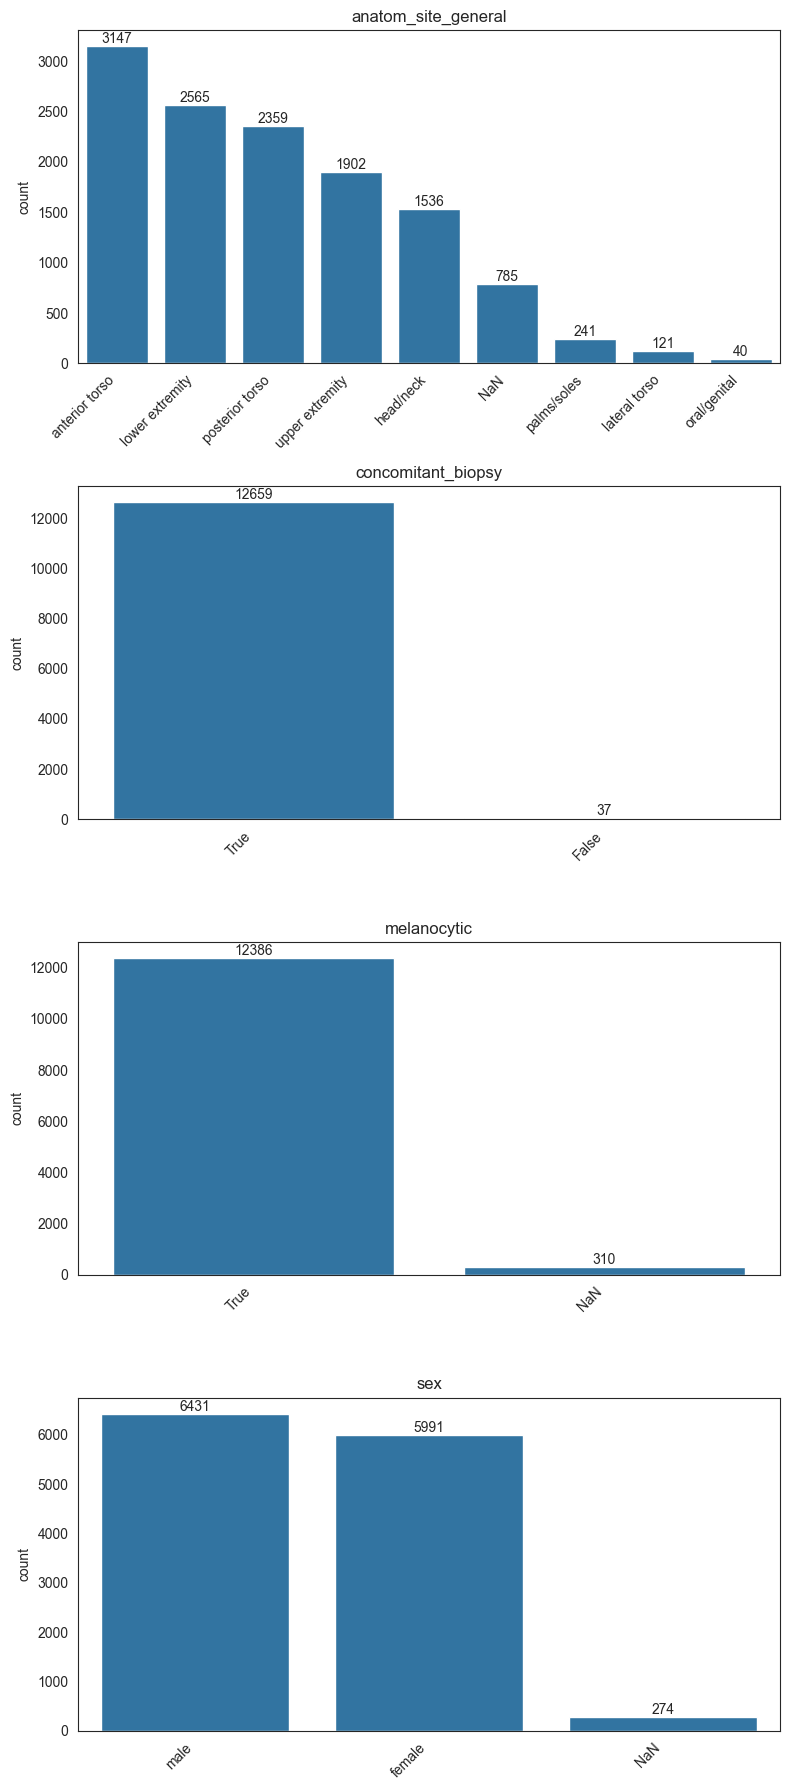

In [6]:
id_cols = ['isic_id', 'lesion_id', 'patient_id']

# Các cột object có missing, loại trừ id; bool (concomitant_biopsy) cũng được xem như object
candidate_cols = df_train.select_dtypes(include=['object', 'bool']).columns
object_missing_cols = [
    c for c in candidate_cols
    if c not in id_cols and (df_train[c].isna().sum() > 0 or df_train[c].dtype == bool)
]

fig, axes = plt.subplots(len(object_missing_cols), 1, figsize=(8, 4.5 * len(object_missing_cols)))
if len(object_missing_cols) == 1:
    axes = [axes]

for ax, c in zip(axes, object_missing_cols):
    data = df_train[c].astype('object').fillna('NaN')
    order = data.value_counts().index
    sns.countplot(x=data, order=order, ax=ax)
    ax.set_title(c)
    ax.set_xlabel('')
    ax.set_ylabel('count')
    ax.tick_params(axis='x', rotation=45)
    for label in ax.get_xticklabels():
        label.set_ha('right')
    for container in ax.containers:
        ax.bar_label(container)

plt.tight_layout()
plt.show()

##### 4. Phân phối nhãn diagnosis

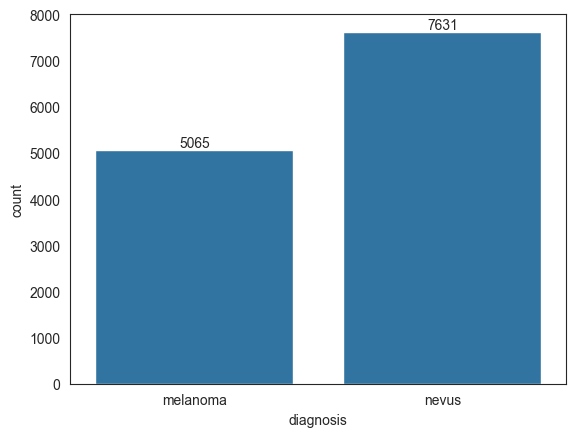

In [7]:
# Plot bar for diagnosis
ax = sns.countplot(data=df_train, x='diagnosis')
for container in ax.containers:
    ax.bar_label(container)
plt.show()


##### 5. Mối quan hệ anatom_site_general với diagnosis

In [8]:
# Tỉ lệ (%) các giá trị anatom_site_general trong từng nhóm diagnosis
pd.crosstab(
    df_train['anatom_site_general'].fillna('NaN'),
    df_train['diagnosis'],
    normalize='columns'
).sort_values('melanoma', ascending=False).round(4) * 100

diagnosis,melanoma,nevus
anatom_site_general,,
anterior torso,22.63,26.22
head/neck,19.07,7.47
lower extremity,17.99,21.67
upper extremity,17.83,13.09
posterior torso,12.95,22.32
NaN,5.98,6.32
palms/soles,2.61,1.43
lateral torso,0.55,1.22
oral/genital,0.39,0.26


In [9]:
# Hiệu số số lượng (melanoma - nevus) trong từng giá trị anatom_site_general
# Âm nghĩa là melanoma có số lượng thấp hơn nevus tại vị trí đó
counts = pd.crosstab(df_train['anatom_site_general'].fillna('NaN'), df_train['diagnosis'])
counts['diff (melanoma - nevus)'] = counts['melanoma'] - counts['nevus']
counts.sort_values('diff (melanoma - nevus)', ascending=False)

diagnosis,melanoma,nevus,diff (melanoma - nevus)
anatom_site_general,,,
head/neck,966,570,396
palms/soles,132,109,23
oral/genital,20,20,0
lateral torso,28,93,-65
upper extremity,903,999,-96
NaN,303,482,-179
lower extremity,911,1654,-743
anterior torso,1146,2001,-855
posterior torso,656,1703,-1047


##### 6. Mối quan hệ sex với diagnosis

In [10]:
# Tỉ lệ (%) sex trong từng nhóm diagnosis
pd.crosstab(
    df_train['sex'].fillna('NaN'),
    df_train['diagnosis'],
    normalize='columns'
).sort_values('melanoma', ascending=False).round(4) * 100

diagnosis,melanoma,nevus
sex,,
male,56.86,46.53
female,39.27,52.44
NaN,3.87,1.02


##### 7. Mối quan hệ age_approx với diagnosis

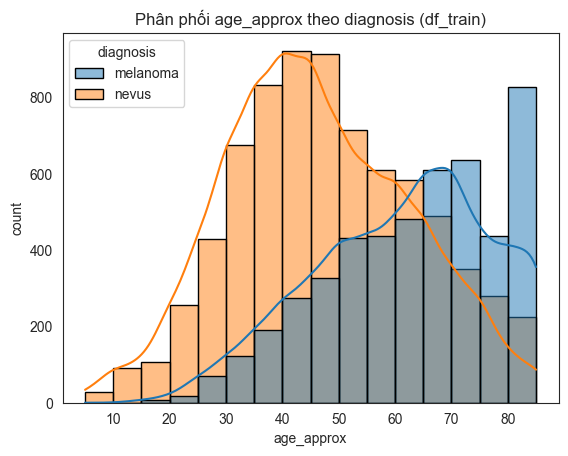

In [11]:
fig, ax = plt.subplots()
sns.histplot(
    data=df_train.dropna(subset=['age_approx']),
    x='age_approx',
    hue='diagnosis',
    bins=bins,
    kde=True,
    edgecolor='black',
    ax=ax,
)

ax.set_xlabel('age_approx')
ax.set_ylabel('count')
ax.set_title('Phân phối age_approx theo diagnosis (df_train)')
plt.show()

In [12]:
def bin_age_by_decade(df, age_col='age_approx', label_col='diagnosis'):
    """Chia age thành các bin độ dài 10 (1-10, 11-20, ...), trả về số lượng + tỉ lệ
    melanoma/nevus và chênh lệch giữa 2 nhóm trong từng bin, sắp xếp diff giảm dần."""
    ages = df[age_col].dropna()
    max_edge = int(np.ceil(ages.max() / 10)) * 10
    edges = list(range(0, max_edge + 10, 10))
    labels = [f"{edges[i] + 1}-{edges[i + 1]}" for i in range(len(edges) - 1)]

    age_bin = pd.cut(df[age_col], bins=edges, labels=labels)

    counts = pd.crosstab(age_bin, df[label_col])
    counts.columns = [f"n_{c}" for c in counts.columns]

    pct = pd.crosstab(age_bin, df[label_col], normalize='columns').round(4) * 100

    result = pd.concat([counts, pct], axis=1)
    result['diff (melanoma - nevus)'] = pct['melanoma'] - pct['nevus']
    return result.sort_values('diff (melanoma - nevus)', ascending=False)


bin_result = bin_age_by_decade(df_train)

print("=== Bin 10 tuổi có chênh lệch melanoma-nevus lớn nhất ===")
print(bin_result)

=== Bin 10 tuổi có chênh lệch melanoma-nevus lớn nhất ===
            n_melanoma  n_nevus  melanoma  nevus  diff (melanoma - nevus)
age_approx                                                               
61-70             1246      839     25.61  11.18                    14.43
71-80              841      411     17.29   5.47                    11.82
81-90              421       94      8.65   1.25                     7.40
51-60              918     1194     18.87  15.91                     2.96
1-10                 0      121      0.00   1.61                    -1.61
11-20               25      362      0.51   4.82                    -4.31
41-50              758     1627     15.58  21.67                    -6.09
21-30              192     1104      3.95  14.71                   -10.76
31-40              464     1755      9.54  23.38                   -13.84


##### 8. Kiểm định cơ chế missing (MCAR vs MAR) cho age_approx, sex, anatom_site_general

Trước khi kiểm định, gộp các giá trị `attribution` gần nhau (cùng viện/trung tâm, chỉ khác cách ghi) thành 1 nhóm chung để tránh pha loãng tín hiệu do quá nhiều category nhỏ lẻ. Sau đó test association (chi-square) giữa missing-indicator của từng cột với các biến quan sát được (`diagnosis`, `attribution_grouped`) và với missing-indicator của 2 cột còn lại. Nếu có association có ý nghĩa thống kê (p < 0.05) → bác bỏ MCAR, gợi ý MAR (not MCAR). Lưu ý: MNAR không thể xác nhận chỉ bằng thống kê trên dữ liệu quan sát được.

In [13]:
from scipy.stats import chi2_contingency

attribution_group_map = {
    'ViDIR Group, Department of Dermatology, Medical University of Vienna': 'Department of Dermatology, Medical University of Vienna',
    'Hospital Clínic de Barcelona': 'Hospital Clinic de Barcelona',
    'Department of Dermatology, Hospital Clínic de Barcelona': 'Hospital Clinic de Barcelona',
    'Sydney Melanoma Diagnostic Center at Royal Prince Alfred Hospital, Pascale Guitera': 'Royal Prince Alfred Hospital',
    'Sydney Melanoma Diagnostic Center at Royal Prince Alfred Hospital': 'Royal Prince Alfred Hospital',
    'Anonymous': 'Other Sources',
    'Dr. Julien Anriot': 'Other Sources',
}

df_train['attribution_grouped'] = df_train['attribution'].replace(attribution_group_map)

print("Số nhóm attribution sau khi gộp:", df_train['attribution_grouped'].nunique())
print(df_train['attribution_grouped'].value_counts())
print()

TARGET_COLS = ['age_approx', 'sex', 'anatom_site_general']
COVARIATES = ['diagnosis', 'attribution_grouped']
ALPHA = 0.05


def check_missingness_mechanism(df, target_cols=TARGET_COLS, covariates=COVARIATES, alpha=ALPHA):
    """Với mỗi cột target, test association (chi-square) giữa missing-indicator của nó và:
    - các covariate quan sát được (diagnosis, attribution_grouped)
    - missing-indicator của các cột target khác
    Nếu có association có ý nghĩa -> gợi ý MAR (not MCAR). Nếu không -> gợi ý MCAR
    (lưu ý: không thể xác nhận MNAR chỉ bằng thống kê trên dữ liệu quan sát được)."""
    results = {}
    missing_flags = {c: df[c].isna() for c in target_cols}

    for col in target_cols:
        indicator = missing_flags[col]
        pvals = {}

        for cov in covariates:
            ct = pd.crosstab(indicator, df[cov].fillna('NaN'))
            _, p, _, _ = chi2_contingency(ct)
            pvals[cov] = p

        for other_col in target_cols:
            if other_col == col:
                continue
            ct = pd.crosstab(indicator, missing_flags[other_col])
            _, p, _, _ = chi2_contingency(ct)
            pvals[f'missing_{other_col}'] = p

        significant = {k: v for k, v in pvals.items() if v < alpha}
        verdict = "MCAR" if not significant else f"MAR (liên hệ với: {list(significant.keys())})"

        results[col] = {'p_values': pvals, 'n_missing': int(indicator.sum()), 'verdict': verdict}

    return results


results = check_missingness_mechanism(df_train)

for col, r in results.items():
    print(f"=== {col} (n_missing={r['n_missing']}) ===")
    for k, v in r['p_values'].items():
        flag = '*' if v < ALPHA else ''
        print(f"  p-value vs {k:20s}: {v:.6g} {flag}")
    print(f"  -> Kết luận: {r['verdict']}")
    print()

Số nhóm attribution sau khi gộp: 7
attribution_grouped
Hospital Clinic de Barcelona                                                                                    4098
Other Sources                                                                                                   3500
Department of Dermatology, Medical University of Vienna                                                         3000
Memorial Sloan Kettering Cancer Center                                                                          1435
Royal Prince Alfred Hospital                                                                                     358
Hospital Italiano de Buenos Aires                                                                                250
The University of Queensland Diamantina Institute, The University of Queensland, Dermatology Research Centre      55
Name: count, dtype: int64

=== age_approx (n_missing=324) ===
  p-value vs diagnosis           : 6.87049e-16 *
  p-value vs at

##### 9. Attribution nào gây ra sự khác biệt dẫn đến kết luận MAR

Với mỗi cột, tính % missing theo từng `attribution_grouped` (đã gộp nhóm ở bước 8) và đóng góp của từng dòng vào thống kê chi-square (`(observed - expected)² / expected`) — giá trị càng cao nghĩa là nguồn đó càng "lệch" so với kỳ vọng nếu missing là ngẫu nhiên, và càng góp phần làm p-value nhỏ ở bước kiểm định MAR phía trên.

In [14]:
diag_counts = pd.crosstab(df_train['attribution_grouped'], df_train['diagnosis'])

rows = []
for col in TARGET_COLS:
    indicator = df_train[col].isna()
    ct = pd.crosstab(df_train['attribution_grouped'], indicator)
    ct.columns = ['not_missing', 'missing']
    ct['total'] = ct['not_missing'] + ct['missing']
    ct['missing_percentage'] = (ct['missing'] / ct['total'] * 100).round(2)

    _, _, _, expected = chi2_contingency(ct[['not_missing', 'missing']])
    ct['chi2_contribution'] = (((ct[['not_missing', 'missing']].values - expected) ** 2 / expected)
                                .sum(axis=1).round(1))

    ct = ct.join(diag_counts)
    ct = ct[['total', 'melanoma', 'nevus', 'missing', 'missing_percentage', 'chi2_contribution']].reset_index()
    ct.insert(0, 'column', col)
    rows.append(ct)

missingness_by_attribution = (
    pd.concat(rows, ignore_index=True)
    .sort_values(['column', 'chi2_contribution'], ascending=[True, False])
    .set_index(['column', 'attribution_grouped'])
)
missingness_by_attribution

total  \
column              attribution_grouped                                         
age_approx          Other Sources                                        3500   
                    Hospital Clinic de Barcelona                         4098   
                    Memorial Sloan Kettering Cancer Center               1435   
                    Royal Prince Alfred Hospital                          358   
                    Hospital Italiano de Buenos Aires                     250   
                    The University of Queensland Diamantina Institu...     55   
                    Department of Dermatology, Medical University o...   3000   
anatom_site_general Hospital Clinic de Barcelona                         4098   
                    Other Sources                                        3500   
                    Department of Dermatology, Medical University o...   3000   
                    Memorial Sloan Kettering Cancer Center               1435   
                    Royal Prince Alfred Hospital                          358   
                    Hospital Italiano de Buenos Aires                     250   
                    The University of Queensland Diamantina Institu...     55   
sex                 Other Sources                                        3500   
                    Hospital Clinic de Barcelona                         4098   
                    Memorial Sloan Kettering Cancer Center               1435   
                    Royal Prince Alfred Hospital                          358   
                    Hospital Italiano de Buenos Aires                     250   
                    The University of Queensland Diamantina Institu...     55   
                    Department of Dermatology, Medical University o...   3000   

                                                                        melanoma  \
column              attribution_grouped                                            
age_approx          Other Sources                                           1303   
                    Hospital Clinic de Barcelona                            2135   
                    Memorial Sloan Kettering Cancer Center                   302   
                    Royal Prince Alfred Hospital                             155   
                    Hospital Italiano de Buenos Aires                        146   
                    The University of Queensland Diamantina Institu...         6   
                    Department of Dermatology, Medical University o...      1018   
anatom_site_general Hospital Clinic de Barcelona                            2135   
                    Other Sources                                           1303   
                    Department of Dermatology, Medical University o...      1018   
                    Memorial Sloan Kettering Cancer Center                   302   
                    Royal Prince Alfred Hospital                             155   
                    Hospital Italiano de Buenos Aires                        146   
                    The University of Queensland Diamantina Institu...         6   
sex                 Other Sources                                           1303   
                    Hospital Clinic de Barcelona                            2135   
                    Memorial Sloan Kettering Cancer Center                   302   
                    Royal Prince Alfred Hospital                             155   
                    Hospital Italiano de Buenos Aires                        146   
                    The University of Queensland Diamantina Institu...         6   
                    Department of Dermatology, Medical University o...      1018   

                                                                        nevus  \
column              attribution_grouped                                         
age_approx          Other Sources                                        2197   
                    Hospital Cli